<a href="https://colab.research.google.com/github/ishanallasanagala/ds2002-fa26/blob/main/notebooks/07-visualization/2026-11-13%20%E2%80%94%20Visualization%20Challenge%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

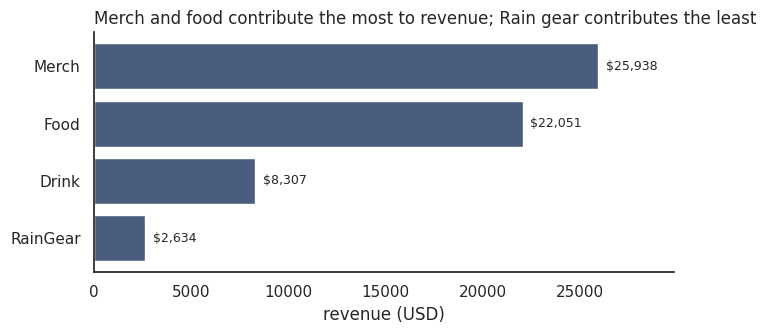

In [2]:
# TODO
s = df.groupby('category')['revenue'].sum().sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(s.index, s.values, color=BLUE)
for y, v in enumerate(s.values):
    ax.text(v + s.max() * 0.015, y, f'${v:,.0f}', va='center', fontsize=9)
ax.set_xlim(0, s.max() * 1.15)
finish(ax, 'Merch and food contribute the most to revenue; Rain gear contributes the least', xlabel='revenue (USD)')
plt.show()

**Caption:** This graph supports vendor contract and inventory budgeting by showing that Merch and Food generate the bulk of the total game-day revenue across the season.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

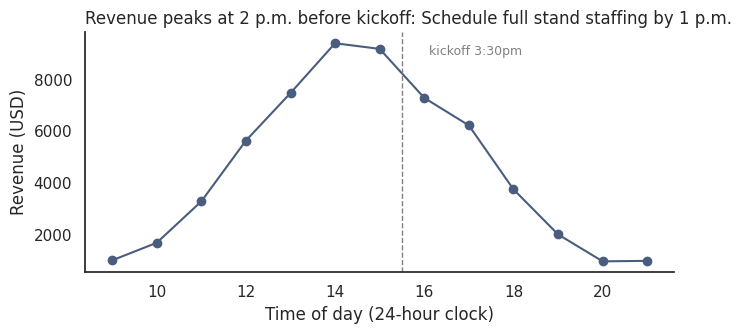

In [3]:
# TODO
hourly_rev = df.groupby('hour')['revenue'].sum()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(hourly_rev.index, hourly_rev.values, marker='o', color=BLUE)
ax.axvline(15.5, ls='--', color='gray', lw=1)
ax.annotate('kickoff 3:30pm', xy=(15.5, hourly_rev.max()), xytext=(16.1, hourly_rev.max() * 0.95), fontsize=9, color='gray')
finish(ax, 'Revenue peaks at 2 p.m. before kickoff: Schedule full stand staffing by 1 p.m.', xlabel='Time of day (24-hour clock)', ylabel='Revenue (USD)')
plt.show()

**Caption:** This chart supports shift scheduling by showing that concession stands need peak staffing between 1pm and 3pm ahead of the 3:30pm kickoff rush, followed by cuts after 5pm to maximize productivity based on revenue contributions at different times.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

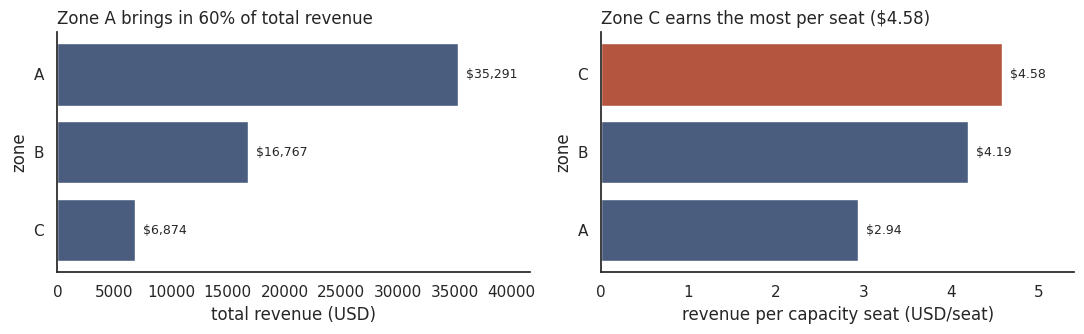

In [4]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
# TODO: two panels -- raw revenue and revenue per capacity
z_raw = df.groupby('zone')['revenue'].sum().sort_values()
z_norm = (z_raw / pd.Series(zone_capacity)).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))

ax1.barh(z_raw.index, z_raw.values, color=BLUE)
for y, v in enumerate(z_raw.values):
    ax1.text(v + z_raw.max() * 0.02, y, f'${v:,.0f}', va='center', fontsize=9)
ax1.set_xlim(0, z_raw.max() * 1.18)
finish(ax1, 'Zone A brings in 60% of total revenue', xlabel='total revenue (USD)', ylabel='zone')

colors = [RUST if idx == z_norm.index[-1] else BLUE for idx in z_norm.index]
ax2.barh(z_norm.index, z_norm.values, color=colors)
for y, v in enumerate(z_norm.values):
    ax2.text(v + z_norm.max() * 0.02, y, f'${v:.2f}', va='center', fontsize=9)
ax2.set_xlim(0, z_norm.max() * 1.18)
finish(ax2, 'Zone C earns the most per seat ($4.58)', xlabel='revenue per capacity seat (USD/seat)', ylabel='zone')

plt.show()

**Caption, and which panel I would present:** These charts compare the three different zones by total amount of revenue and also by revenue produced per seat. I would present the chart on the right comparing revenue produced per seat because I could emphasize that seats in Zone A should be deprioritized for sale due to having the least value per seat.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

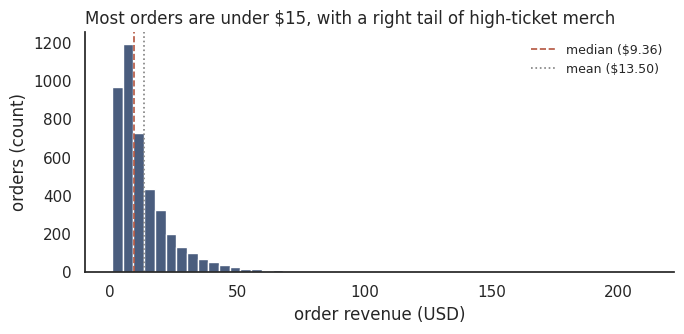

In [5]:
# TODO
med = df['revenue'].median()
mean = df['revenue'].mean()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(df['revenue'], bins=50, color=BLUE, edgecolor='white')
ax.axvline(med, ls='--', color=RUST, lw=1.2, label=f'median (${med:.2f})')
ax.axvline(mean, ls=':', color='gray', lw=1.2, label=f'mean (${mean:.2f})')
ax.legend(frameon=False, fontsize=9)
finish(ax, 'Most orders are under $15, with a right tail of high-ticket merch', xlabel='order revenue (USD)', ylabel='orders (count)')
plt.show()

**Caption:** This chart supports combo pricing by showing a right-skewed distribution where the typical order is small (median 9.36 dollars vs mean 13.50 dollars), meaning a $15 bundle targets the bulk of small checkouts while a few expensive merch orders pull up the average.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

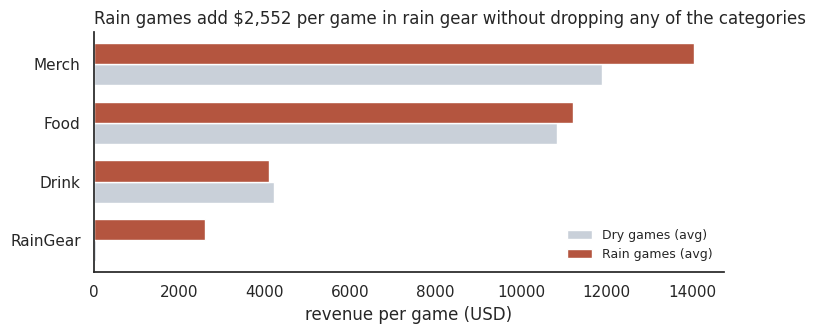

In [6]:
# TODO
w_cat = df.groupby(['category', 'weather'])['revenue'].sum().unstack(fill_value=0)/2
w_cat = w_cat.loc[w_cat.sum(axis=1).sort_values().index]
rain_gain = w_cat.loc['RainGear', 'rain'] - w_cat.loc['RainGear', 'dry']

y = np.arange(len(w_cat))
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.barh(y - 0.18, w_cat['dry'], height=0.36, color=GRAY, label='Dry games (avg)')
ax.barh(y + 0.18, w_cat['rain'], height=0.36, color=RUST, label='Rain games (avg)')
ax.set_yticks(y, w_cat.index)
ax.legend(frameon=False, fontsize=9)
finish(ax, f'Rain games add ${rain_gain:,.0f} per game in rain gear without dropping any of the categories', xlabel='revenue per game (USD)')
plt.show()

**Caption:** This chart supports weather-based inventory staging by showing that wet games increase in rain gear and merch revenue while food and drink revenue stay steady.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [7]:
scores = {
    'chart 1 (category)': 5,     # TODO: out of 6
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 5,
    'chart 4 (distribution)': 5,
    'chart 5 (your choice)': 6,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         5/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             5/6  [ok]
chart 4 (distribution)     5/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 5.4/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

Chart 3 changed my mind the most about what the data was showing. In the raw totals, Zone A looks like the clear standout at $35,291 while Zone C looks like an afterthought at $6,874 of total revenue produced. However, once we divided by seat capacity (12,000 seats in Zone A vs. 1,500 in Zone C), the ranking flipped completely. Zone C actually brings in the most per seat ($4.58) (despite producign the least total revenue by far) and Zone B comes in second ($4.19), while Zone A lags at $2.94 per seat. This elucidated exactly how the value per seat compared across to the total revenue produced by the seats. Chart 5 had a similar impact on me for the role of RainGear, showing that it only looks tiny in Chart 1 because it sells almost exclusively during the two rainy games rather than across all four games.

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

The left panel (raw revenue by zone) is the right view to show an operations manager handling logistics like where to prepare inventory to sell and how many cashiers and restockers each zone needs. This is because the amount of support provided to a zone should be determined total dollars and orders to a section, regardless of how many seats a section has. The right panel (revenue per capacity seat) is the right view to show a commercial manager analying selling efficiency. For example, this could help with tasks such as figuring out whether Zone A's 12,000-seat crowd is underserved by long concession lines or deciding where a new express kiosk would result in the highest gain in revenue per fan in a set.